# Sleep states and seizures in Spyglass: DANDI:001888 (Gonzalez-Sulser lab)

The lab scored two 24-hour baseline windows of each recording with its
[automatic sleep scorer](https://github.com/Gonzalez-Sulser-Team/AUTOMATIC-SLEEP-SCORER): every 5-second epoch is
Wake, NREM or REM. Its seizure detection lists the spike-wave discharges (seizures) of each window with their start
and stop times. Both are `TimeIntervals` tables in the files' `behavior` processing module, `sleep_states` and
`seizure_events`, and this notebook reads them back through a Spyglass database.

Spyglass has no tables for sleep scoring or seizures upstream. They are proposed in
[LorenFrankLab/spyglass#1726](https://github.com/LorenFrankLab/spyglass/pull/1726). Until it is merged, the
environment installs them from the `gonzalez-sulser-example-v1` tag of the CatalystNeuro Spyglass fork (see the
[Spyglass ingestion docs](../../docs/spyglass_ingestion.md)):

- `SleepStateScoring` has one row per `TimeIntervals` with a `sleep_state` column, and its `.Epoch` part one row per
  scored epoch: start, stop and state.
- `SeizureEvents` has one row per `TimeIntervals` named `seizure_events`, and its `.Event` part one row per seizure:
  start and stop.

Because the epochs and seizures are rows of the database, they can be counted and restricted in queries. The other
columns of the two tables (`sleep_score`, `baseline_window`, `duration`) stay in the NWB file and come back with
`fetch1_dataframe()`. The files' other analysis results (spike-wave discharge flags per epoch, seizure counts per
Zeitgeber hour and the power spectra of each state) are not ingested.

**Running it:** this notebook runs in the `spyglass-gonzalez-sulser-lab-env` conda env inside WSL2, created with `../bootstrap_wsl.sh`. The database is the `spyglass-db` Docker container on port 3306; see `../docker-compose.yml`, `../dj_local_conf.json` and the [Spyglass ingestion docs](../../docs/spyglass_ingestion.md). Ingest the files with `../insert_full_session.py` first.

In [1]:
from pathlib import Path

import datajoint as dj

# Load the connection config BEFORE importing spyglass: spyglass declares its schemas
# at import time and would otherwise connect with default settings (including TLS,
# which the local Docker MySQL doesn't use).
dj.config.load(str(Path("..") / "dj_local_conf.json"))
dj.conn(use_tls=False)

[2026-11-19 11:30:24,250][INFO]: DataJoint is configured from /mnt/c/Users/amtra/CatalystNeuro/gonzalez-sulser-lab-to-nwb/src/gonzalez_sulser_lab_to_nwb/hristova_2025/spyglass/dj_local_conf.json


[2026-11-19 11:30:24,259][INFO]: DataJoint 0.14.10 connected to root@127.0.0.1:3306


DataJoint connection (connected) root@127.0.0.1:3306

In [2]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from spyglass.common import (
    ImportedEEG,
    IntervalList,
    Nwbfile,
    SeizureEvents,
    Session,
    SleepStateScoring,
    Subject,
)

GENOTYPE_LABELS = {"LE-Grin2bem1Mcwi": "Het", "WT": "WT"}
STATES = ["Wake", "NREM", "REM"]
STATE_COLORS = {"Wake": "tab:orange", "NREM": "tab:blue", "REM": "tab:green"}

sessions = (
    pd.DataFrame((Session * Subject).fetch("nwb_file_name", "subject_id", "sex", "genotype", as_dict=True))
    .assign(genotype=lambda df: df["genotype"].map(GENOTYPE_LABELS))
    .sort_values(["genotype", "subject_id"])
    .reset_index(drop=True)
)
example = sessions[sessions["subject_id"] == "GRIN2B-424"].iloc[0]
example_key = {"nwb_file_name": example["nwb_file_name"]}

## Checks

Every session should have one sleep scoring table, `sleep_states`, with 34,560 epochs of 5 seconds (two 24-hour
windows), all inside the two baseline windows of `IntervalList`. Every session should have one seizure table except
GRIN2B-238 and GRIN2B-375: these two wild-type rats had no seizure in either window, so their files have no
`seizure_events` table. Every seizure should lie inside a baseline window.

In [3]:
SEIZURE_FREE = {"GRIN2B-238", "GRIN2B-375"}


def window_bounds(key):
    return np.array(
        [
            (IntervalList & key & {"interval_list_name": window}).fetch1("valid_times")[0]
            for window in ("baseline_window_1", "baseline_window_2")
        ]
    )


def inside_windows(starts, stops, bounds):
    return np.any((starts[:, None] >= bounds[:, 0] - 1e-6) & (stops[:, None] <= bounds[:, 1] + 1e-6), axis=1)


for row in sessions.itertuples():
    key = {"nwb_file_name": row.nwb_file_name}
    bounds = window_bounds(key)

    scoring = (SleepStateScoring & key).fetch(as_dict=True)
    assert [s["scoring_name"] for s in scoring] == ["sleep_states"], f"{row.subject_id}: scoring tables"
    starts, stops = (SleepStateScoring.Epoch & key).fetch("start_time", "stop_time")
    assert len(starts) == scoring[0]["n_epochs"] == 34560, f"{row.subject_id}: {len(starts)} epochs"
    assert np.allclose(stops - starts, 5.0), f"{row.subject_id}: epoch lengths"
    assert inside_windows(starts, stops, bounds).all(), f"{row.subject_id}: epochs outside the windows"

    seizures = (SeizureEvents & key).fetch(as_dict=True)
    if row.subject_id in SEIZURE_FREE:
        assert not seizures, f"{row.subject_id}: unexpected seizure table"
        continue
    assert [s["seizure_table_name"] for s in seizures] == ["seizure_events"], f"{row.subject_id}: seizure tables"
    starts, stops = (SeizureEvents.Event & key).fetch("start_time", "stop_time")
    assert len(starts) == seizures[0]["n_events"], f"{row.subject_id}: seizure rows"
    assert inside_windows(starts, stops, bounds).all(), f"{row.subject_id}: seizures outside the windows"

print(f"All checks passed for {len(sessions)} session(s).")

All checks passed for 24 session(s).


## 1. Time in each state

The duration of each state is summed in the database, per session and state, with `dj.U(...).aggr()`. Over the 48
scored hours, the rats are awake about two thirds of the time.

Wake             NREM              REM       
              mean    std      mean    std      mean    std
genotype                                                   
Het       0.646312  0.033  0.320723  0.026  0.032965  0.012
WT        0.645695  0.046  0.308857  0.039  0.045448  0.011

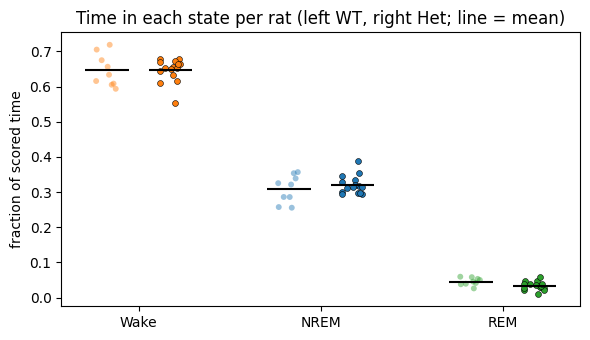

In [4]:
hours = (
    dj.U("nwb_file_name", "sleep_state")
    .aggr(SleepStateScoring.Epoch, hours="sum(stop_time - start_time) / 3600")
    .fetch(format="frame")
    .reset_index()
    .pivot(index="nwb_file_name", columns="sleep_state", values="hours")[STATES]
)
fractions = hours.div(hours.sum(axis=1), axis=0)
fractions = sessions.set_index("nwb_file_name")[["subject_id", "genotype"]].join(fractions)

fig, ax = plt.subplots(figsize=(6, 3.5))
for i, state in enumerate(STATES):
    for j, genotype in enumerate(["WT", "Het"]):
        values = fractions.loc[fractions["genotype"] == genotype, state]
        x = i + (j - 0.5) * 0.35 + np.random.default_rng(0).uniform(-0.06, 0.06, len(values))
        ax.scatter(x, values, s=18, color=STATE_COLORS[state], alpha=1.0 if genotype == "Het" else 0.45,
                   label=genotype if i == 0 else None, edgecolor="k" if genotype == "Het" else "none", lw=0.4)
        ax.hlines(values.mean(), i + (j - 0.5) * 0.35 - 0.12, i + (j - 0.5) * 0.35 + 0.12, color="k")
ax.set_xticks(range(len(STATES)))
ax.set_xticklabels(STATES)
ax.set_ylabel("fraction of scored time")
ax.set_title("Time in each state per rat (left WT, right Het; line = mean)")
plt.tight_layout()

fractions.groupby("genotype")[STATES].agg(["mean", "std"]).round(3)

## 2. A hypnogram with seizures

The epochs of one session come from `SleepStateScoring.Epoch` and its seizures from `SeizureEvents.Event`, both
restricted to the first baseline window. The seizures are drawn above the hypnogram.

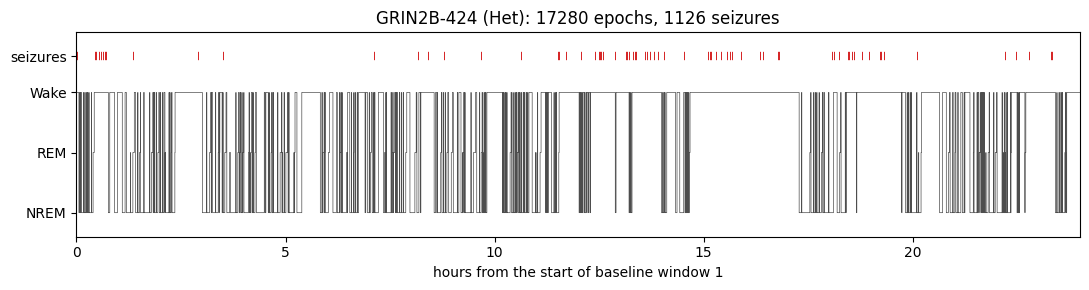

In [5]:
window_start, window_stop = window_bounds(example_key)[0]
in_window = f"start_time >= {window_start} and stop_time <= {window_stop}"
epochs = (SleepStateScoring.Epoch & example_key & in_window).fetch(format="frame").reset_index()
seizures = (SeizureEvents.Event & example_key & in_window).fetch(format="frame").reset_index()

state_level = {"Wake": 2, "REM": 1, "NREM": 0}
t = (epochs["start_time"] - window_start) / 3600
fig, ax = plt.subplots(figsize=(11, 3))
ax.step(t, epochs["sleep_state"].map(state_level), where="post", lw=0.5, color="0.3")
for start, stop in zip(seizures["start_time"], seizures["stop_time"]):
    ax.plot([(start - window_start) / 3600, (stop - window_start) / 3600], [2.6, 2.6], color="tab:red", lw=6,
            solid_capstyle="butt")
ax.set_yticks([0, 1, 2, 2.6])
ax.set_yticklabels(["NREM", "REM", "Wake", "seizures"])
ax.set_ylim(-0.4, 3.0)
ax.set_xlim(0, 24)
ax.set_xlabel("hours from the start of baseline window 1")
ax.set_title(f"{example['subject_id']} ({example['genotype']}): {len(epochs)} epochs, {len(seizures)} seizures")
plt.tight_layout()

## 3. Seizures per rat

The number of seizures and their total duration per session are computed in the database. All heterozygous rats
but one have 18 to 44 seizures per hour; GRIN2B-228 has 2 seizures in its file, both in the second window. Among
the wild-type rats, three have 2 to 5 per hour, GRIN2B-378 has 19 seizures in 48 hours, and the other five have 0
to 2.

/tmp/ipykernel_4005/2728240063.py:9: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  .fillna({"n_seizures": 0, "seizure_minutes": 0.0})


n_seizures           seizure_minutes             seizures_per_hour  \
               mean min   max            mean  min    max              mean   
genotype                                                                      
Het          1430.5   2  2121           119.6  0.0  249.7              29.8   
WT             62.8   0   225             1.6  0.0    6.1               1.3   

                     
          min   max  
genotype             
Het       0.0  44.2  
WT        0.0   4.7

,subject_id,sex,genotype,n_seizures,seizure_minutes,seizures_per_hour
0,GRIN2B-129,M,Het,1569,123.17,32.69
1,GRIN2B-130,M,Het,1014,74.95,21.12
2,GRIN2B-131,M,Het,1632,125.30,34.00
3,GRIN2B-137,F,Het,1173,59.38,24.44
4,GRIN2B-138,F,Het,1787,124.81,37.23
5,GRIN2B-139,F,Het,1893,227.00,39.44
6,GRIN2B-227,M,Het,1915,158.79,39.90
7,GRIN2B-228,M,Het,2,0.03,0.04
8,GRIN2B-229,M,Het,887,40.74,18.48
9,GRIN2B-236,F,Het,1516,138.93,31.58


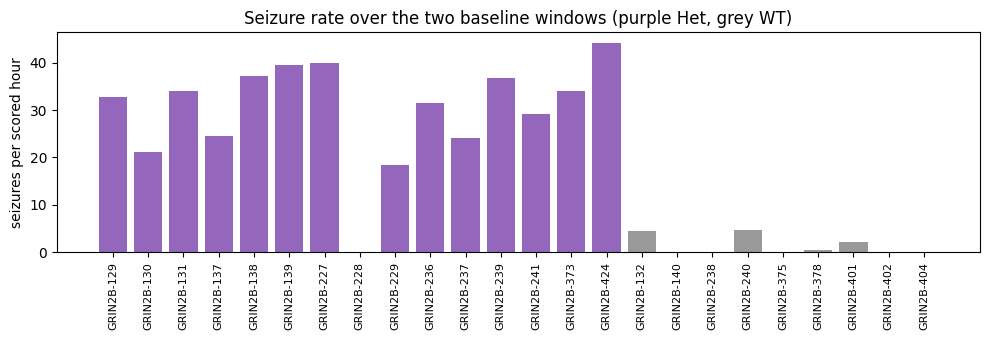

In [6]:
seizure_stats = (
    dj.U("nwb_file_name")
    .aggr(SeizureEvents.Event, n_seizures="count(*)", seizure_minutes="sum(stop_time - start_time) / 60")
    .fetch(format="frame")
)
seizure_stats = (
    sessions.set_index("nwb_file_name")[["subject_id", "sex", "genotype"]]
    .join(seizure_stats)
    .fillna({"n_seizures": 0, "seizure_minutes": 0.0})
    .astype({"n_seizures": int, "seizure_minutes": float})
)
seizure_stats["seizures_per_hour"] = seizure_stats["n_seizures"] / 48

fig, ax = plt.subplots(figsize=(10, 3.5))
colors = seizure_stats["genotype"].map({"Het": "tab:purple", "WT": "0.6"})
ax.bar(seizure_stats["subject_id"], seizure_stats["seizures_per_hour"], color=colors)
ax.set_ylabel("seizures per scored hour")
ax.tick_params(axis="x", rotation=90, labelsize=8)
ax.set_title("Seizure rate over the two baseline windows (purple Het, grey WT)")
plt.tight_layout()

display(seizure_stats.groupby("genotype")[["n_seizures", "seizure_minutes", "seizures_per_hour"]].agg(["mean", "min", "max"]).round(1))
seizure_stats.round(2).reset_index(drop=True)

## 4. Seizures by sleep state

Each seizure is assigned the state of the epoch in which it starts, by matching start times between the two part
tables. The rate of seizures in a state is the number that start in it divided by the time spent in it. The scorer
labels epochs before relabelling spike-wave discharges (see the description of `sleep_states`), so a seizure's
epoch carries the state the scorer gave it. In the heterozygous rats most seizures start in epochs scored as Wake.

,Wake,NREM,REM
genotype,,,
Het,42.811041,6.450209,3.018805
WT,2.552336,0.035911,0.0


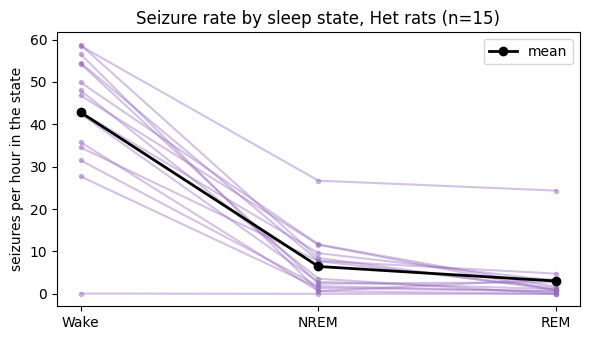

In [7]:
all_epochs = (
    SleepStateScoring.Epoch.fetch(format="frame").reset_index()[["nwb_file_name", "start_time", "sleep_state"]]
    .sort_values("start_time")
)
all_seizures = (
    SeizureEvents.Event.fetch(format="frame").reset_index()[["nwb_file_name", "start_time", "stop_time"]]
    .sort_values("start_time")
)
seizure_states = pd.merge_asof(
    all_seizures, all_epochs, on="start_time", by="nwb_file_name", direction="backward"
)

counts = seizure_states.groupby(["nwb_file_name", "sleep_state"]).size().unstack(fill_value=0).reindex(columns=STATES, fill_value=0)
rates = (counts / hours).dropna()
rates = sessions.set_index("nwb_file_name")[["subject_id", "genotype"]].join(rates, how="inner")

fig, ax = plt.subplots(figsize=(6, 3.5))
het = rates[rates["genotype"] == "Het"]
for _, row in het.iterrows():
    ax.plot(STATES, row[STATES], color="tab:purple", alpha=0.4, marker="o", ms=3)
ax.plot(STATES, het[STATES].mean(), color="k", marker="o", lw=2, label="mean")
ax.set_ylabel("seizures per hour in the state")
ax.set_title(f"Seizure rate by sleep state, Het rats (n={len(het)})")
ax.legend()
plt.tight_layout()

rates.groupby("genotype")[STATES].mean().round(1)

## 5. The EEG around a seizure

The seizure tables give times; the EEG is in `ImportedEEG` (see the [EEG and EMG notebook](spyglass_eeg_emg_tutorial.ipynb)).
Below, a seizure of the example session's first window with the session's median duration, with 5 seconds on each
side, on the EEG channel the lab used for sleep scoring (`M2_anterior_R`) and on one EMG channel. The scored state
of each epoch is shaded behind the trace.

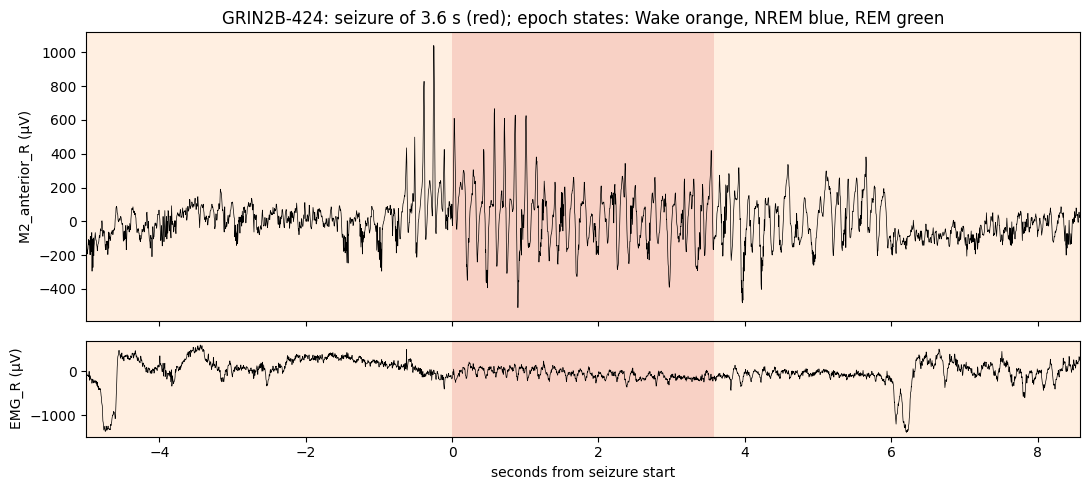

In [8]:
def load_channel(key, series_name, channel_name, start, stop):
    """Times (s) and samples of one channel of a series between start and stop."""
    nwbfile = (Nwbfile & key).fetch_nwb()[0]
    channel_ids = nwbfile.electrodes.to_dataframe()["channel_name"]
    (Nwbfile & key).close_nwb()
    electrode_id = int(channel_ids[channel_ids == channel_name].index[0])

    eeg_object_id = (ImportedEEG & key & {"name": series_name}).fetch1("eeg_object_id")
    column = (ImportedEEG.Electrode & key & {"eeg_object_id": eeg_object_id, "electrode_id": electrode_id}).fetch1("region_index")
    es = ImportedEEG().nwb_object({**key, "eeg_object_id": eeg_object_id})
    first, last = (int(round((t - es.starting_time) * es.rate)) for t in (start, stop))
    data = np.asarray(es.data[first:last, column]) * es.conversion
    return es.starting_time + np.arange(first, last) / es.rate, data


durations = seizures.assign(duration=seizures["stop_time"] - seizures["start_time"])
seizure = durations.iloc[(durations["duration"] - durations["duration"].median()).abs().argmin()]
start, stop = seizure["start_time"] - 5, seizure["stop_time"] + 5
nearby = (SleepStateScoring.Epoch & example_key & f"stop_time > {start} and start_time < {stop}").fetch(format="frame").reset_index()

fig, axes = plt.subplots(2, 1, figsize=(11, 5), sharex=True, gridspec_kw={"height_ratios": [3, 1]})
for ax, (series_name, channel_name) in zip(axes, [("EEGElectricalSeries", "M2_anterior_R"), ("EMGElectricalSeries", "EMG_R")]):
    times, data = load_channel(example_key, series_name, channel_name, start, stop)
    for epoch in nearby.itertuples():
        ax.axvspan(epoch.start_time - seizure["start_time"], epoch.stop_time - seizure["start_time"],
                   color=STATE_COLORS[epoch.sleep_state], alpha=0.12, lw=0)
    ax.axvspan(0, seizure["stop_time"] - seizure["start_time"], color="tab:red", alpha=0.15, lw=0)
    ax.plot(times - seizure["start_time"], (data - np.median(data)) * 1e6, color="k", lw=0.5)
    ax.set_ylabel(f"{channel_name} (µV)")
axes[0].set_title(
    f"{example['subject_id']}: seizure of {seizure['duration']:.1f} s (red); epoch states: "
    + ", ".join(f"{state} {color.split(':')[1]}" for state, color in STATE_COLORS.items())
)
axes[-1].set_xlabel("seconds from seizure start")
plt.xlim(-5, seizure["stop_time"] - seizure["start_time"] + 5)
plt.tight_layout()

## 6. The other columns, from the file

`fetch1_dataframe()` reads one table back from the NWB file with all its columns: here the numeric `sleep_score`,
the `baseline_window` each row belongs to, and the seizure `duration` as the lab computed it.

In [9]:
display((SleepStateScoring & example_key).fetch1_dataframe().head())
(SeizureEvents & example_key).fetch1_dataframe().head()

,start_time,stop_time,sleep_score,sleep_state,baseline_window
id,,,,,
0,70980.0,70985.0,0,Wake,baseline_window_1
1,70985.0,70990.0,0,Wake,baseline_window_1
2,70990.0,70995.0,0,Wake,baseline_window_1
3,70995.0,71000.0,0,Wake,baseline_window_1
4,71000.0,71005.0,0,Wake,baseline_window_1


,start_time,stop_time,duration,baseline_window
id,,,,
0,71000.20,71006.56,6.37,baseline_window_1
1,71010.54,71011.53,0.99,baseline_window_1
2,71020.09,71047.54,27.45,baseline_window_1
3,71050.32,71054.10,3.78,baseline_window_1
4,71063.65,71075.78,12.13,baseline_window_1


## Summary

- `SleepStateScoring.Epoch` holds the 34,560 scored epochs of every session and `SeizureEvents.Event` the seizures
  of the 22 sessions that have any, so time per state, seizure counts and durations come from database queries.
- Combined with `ImportedEEG`, the seizure times select the EEG and EMG around each event, without reading more
  of the files than the plotted seconds.
- The files' other analysis results (spike-wave discharge flags per epoch, seizure counts per Zeitgeber hour and
  the power spectra of each state) stay in the NWB files. Whether the lab's sleep analysis could run as a Spyglass
  pipeline, from `ImportedEEG` to these tables, is an open idea (see the
  [ingestion notes](../spyglass_ingestion_notes.md)).